# CSET485 – AI and Society · Assignment #1
## Stress-testing a predictive model on the COMPAS Recidivism dataset

**Roll number ends in `2` → assigned dataset: COMPAS Recidivism Risk Score Dataset**
**Last 3 digits of roll number = `012` → `random_state = 12`** for the 70 % / 30 % train–test split.

This Google Colab notebook is fully reproducible: *Runtime → Run all* regenerates every number, table and chart cited in the PDF report.

**Contents**
0. Setup & data loading
1. Data preprocessing (missing values, encoding, scaling, outliers)
2. Part 1 – Build: Model A (OLS on `decile_score`) vs Model B (logistic on recidivism) and the mismatch analysis
3. Part 2.1 – Simpson's paradox hunt
4. Part 2.2 – Omitted-variable bias
5. Part 2.3 – Adversarial subset construction
6. Part 2.4 – Fairness trade-off analysis
7. Summary of key numbers

## 0. Setup & data loading

In [1]:
# All libraries below are pre-installed on Google Colab.
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

SEED = 12          # last three digits of roll number: 012
TEST_SIZE = 0.30   # 70 % train / 30 % test
np.random.seed(SEED)
RESULTS = {}       # collects every headline number cited in the report

In [2]:
DATA_URL = "https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv"
try:
    raw = pd.read_csv(DATA_URL)
    assert "decile_score" in raw.columns
except Exception:
    # fallback: upload the CSV to the Colab session (Files panel) if the URL is unreachable
    raw = pd.read_csv("compas-scores-two-years.csv")
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (7214, 53)


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,juv_fel_count,decile_score,juv_misd_count,juv_other_count,priors_count,days_b_screening_arrest,c_jail_in,c_jail_out,c_case_number,c_offense_date,...,is_violent_recid,vr_case_number,vr_charge_degree,vr_offense_date,vr_charge_desc,type_of_assessment,decile_score.1,score_text,screening_date,v_type_of_assessment,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,0,1,0,0,0,-1.0,2013-08-13 06:03:42,2013-08-14 05:41:20,13011352CF10A,2013-08-13,...,0,NaN,NaN,NaN,NaN,Risk of Recidivism,1,Low,2013-08-14,Risk of Violence,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,0,3,0,0,0,-1.0,2013-01-26 03:45:27,2013-02-05 05:36:53,13001275CF10A,2013-01-26,...,1,13009779CF10A,(F3),2013-07-05,Felony Battery (Dom Strang),Risk of Recidivism,3,Low,2013-01-27,Risk of Violence,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,0,4,0,1,4,-1.0,2013-04-13 04:58:34,2013-04-14 07:02:04,13005330CF10A,2013-04-13,...,0,NaN,NaN,NaN,NaN,Risk of Recidivism,4,Low,2013-04-14,Risk of Violence,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,0,8,1,0,1,NaN,NaN,NaN,13000570CF10A,2013-01-12,...,0,NaN,NaN,NaN,NaN,Risk of Recidivism,8,High,2013-01-13,Risk of Violence,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,0,1,0,0,2,NaN,NaN,NaN,12014130CF10A,NaN,...,0,NaN,NaN,NaN,NaN,Risk of Recidivism,1,Low,2013-03-26,Risk of Violence,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


## 1. Data preprocessing

### 1.1 Row filtering (following ProPublica's original analysis)
ProPublica's analysis keeps only rows where the COMPAS screening is close to the arrest that triggered it. We apply the same four filters:
* `days_b_screening_arrest` between −30 and +30 (otherwise the score may not belong to this charge);
* `is_recid != -1` (no recidivism record could be found);
* `c_charge_degree != 'O'` (ordinary traffic offences, which do not lead to jail);
* `score_text != 'N/A'`.

In [3]:
df = raw[(raw.days_b_screening_arrest <= 30) & (raw.days_b_screening_arrest >= -30) &
         (raw.is_recid != -1) & (raw.c_charge_degree != "O") & (raw.score_text != "N/A")].copy()
print("Rows after ProPublica filters:", len(df), f"(removed {len(raw)-len(df)})")
RESULTS["n_raw"] = int(len(raw)); RESULTS["n_clean"] = int(len(df))

Rows after ProPublica filters: 6172 (removed 1042)


### 1.2 Target variables
* **Model A target:** `decile_score` (1–10, continuous risk score).
* **Model B target:** the assignment calls it `is_recidivist`. The dataset provides `two_year_recid` (1 = re-offended within two years of the screening, the outcome COMPAS claims to predict). We rename it `is_recidivist`.

### 1.3 Feature selection
We use only information known at screening time: `age`, `sex`, `race`, `priors_count`, three juvenile counts, the charge degree, and jail length of stay. We **exclude** all `r_*`, `vr_*`, `is_recid`, `event`, `start/end` (these are outcome information → target leakage), and also `decile_score`/`v_decile_score` from Model B's features (they are COMPAS outputs, not inputs). `age_cat` is dropped because it duplicates `age`.

In [4]:
df["is_recidivist"] = df["two_year_recid"].astype(int)
df["length_of_stay"] = (pd.to_datetime(df.c_jail_out) - pd.to_datetime(df.c_jail_in)).dt.days

keep = ["age", "sex", "race", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count",
        "c_charge_degree", "length_of_stay", "decile_score", "is_recidivist"]
df = df[keep].copy()
print("Missing values per column (selected features):")
print(df.isna().sum())

Missing values per column (selected features):
age                0
sex                0
race               0
priors_count       0
juv_fel_count      0
juv_misd_count     0
juv_other_count    0
c_charge_degree    0
length_of_stay     0
decile_score       0
is_recidivist      0
dtype: int64


### 1.4 Missing values
After the ProPublica filters, none of the selected columns has missing values (the 307 rows that lacked `c_jail_in`/`c_jail_out` in the raw file are exactly the rows that lacked `days_b_screening_arrest` and were already removed). The code below still imputes defensively with the training-set median so the pipeline would not break on a different extract.

### 1.5 Outliers
* `length_of_stay` is extremely right-skewed (median 1 day, max ≈ 800 days) and contains a few −1 values caused by same-day timestamp errors. We **clip negatives to 0** and apply a **log1p transform** so a handful of very long stays do not dominate the linear models.
* `priors_count` (0–38) and the juvenile counts are also skewed, but large values are genuine and highly predictive, so they are **kept unchanged**; we only report how many are IQR outliers.

In [5]:
df["length_of_stay"] = df["length_of_stay"].fillna(df["length_of_stay"].median()).clip(lower=0)

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())

outlier_report = pd.DataFrame({c: {"min": df[c].min(), "median": df[c].median(), "max": df[c].max(),
                                   "IQR outliers": iqr_outliers(df[c])}
                               for c in ["age", "priors_count", "juv_fel_count", "juv_misd_count",
                                         "juv_other_count", "length_of_stay"]}).T
print(outlier_report)
RESULTS["outliers"] = outlier_report.astype(float).to_dict(orient="index")
df["log_length_of_stay"] = np.log1p(df["length_of_stay"])

                  min  median    max  IQR outliers
age              18.0    31.0   96.0          51.0
priors_count      0.0     1.0   38.0         492.0
juv_fel_count     0.0     0.0   20.0         208.0
juv_misd_count    0.0     0.0   13.0         352.0
juv_other_count   0.0     0.0    9.0         461.0
length_of_stay    0.0     1.0  799.0        1154.0


### 1.6 Categorical encoding
* `sex` → `male` (1 = Male, 0 = Female).
* `c_charge_degree` → `felony` (1 = F, 0 = M).
* `race` → one-hot dummies with **Caucasian as the reference** category. Asian (n≈31) and Native American (n≈11) are too small to estimate reliably and are merged into `Other`, giving dummies `race_African_American`, `race_Hispanic`, `race_Other`.

In [6]:
df["race_grp"] = df["race"].replace({"Asian": "Other", "Native American": "Other"})
df["male"] = (df["sex"] == "Male").astype(int)
df["felony"] = (df["c_charge_degree"] == "F").astype(int)
for r in ["African-American", "Hispanic", "Other"]:
    df["race_" + r.replace("-", "_")] = (df["race_grp"] == r).astype(int)

FEATURES = ["age", "male", "race_African_American", "race_Hispanic", "race_Other",
            "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count",
            "felony", "log_length_of_stay"]
print(df["race_grp"].value_counts())
print("Base rate of two-year recidivism:", round(df.is_recidivist.mean(), 4))
RESULTS["race_counts"] = df["race_grp"].value_counts().to_dict()
RESULTS["sex_counts"] = df["sex"].value_counts().to_dict()
RESULTS["base_rate"] = float(df.is_recidivist.mean())
df[FEATURES].describe().T

race_grp
African-American    3175
Caucasian           2103
Hispanic             509
Other                385
Name: count, dtype: int64
Base rate of two-year recidivism: 0.4551


,count,mean,std,min,25%,50%,75%,max
age,6172.0,34.534511,11.730938,18.0,25.0,31.000000,42.000000,96.000000
male,6172.0,0.809624,0.392629,0.0,1.0,1.000000,1.000000,1.000000
race_African_American,6172.0,0.514420,0.499833,0.0,0.0,1.000000,1.000000,1.000000
race_Hispanic,6172.0,0.082469,0.275101,0.0,0.0,0.000000,0.000000,1.000000
race_Other,6172.0,0.062378,0.241861,0.0,0.0,0.000000,0.000000,1.000000
priors_count,6172.0,3.246436,4.743770,0.0,0.0,1.000000,4.000000,38.000000
juv_fel_count,6172.0,0.059300,0.463599,0.0,0.0,0.000000,0.000000,20.000000
juv_misd_count,6172.0,0.091218,0.497872,0.0,0.0,0.000000,0.000000,13.000000
juv_other_count,6172.0,0.110661,0.470731,0.0,0.0,0.000000,0.000000,9.000000
felony,6172.0,0.643227,0.479086,0.0,0.0,1.000000,1.000000,1.000000


### 1.7 Train–test split and feature scaling
70 / 30 split with `random_state = 12`, stratified on the binary outcome so both sets have the same recidivism rate. A `StandardScaler` is **fit on the training set only** and applied to both sets (no test-set leakage). Scaling does not change the predictions of un-penalised OLS / logistic regression; it makes the sklearn coefficients comparable ("effect of a one-SD change"). In Part 2 we fit `statsmodels` models on the **unscaled** features so coefficients keep their natural units (per year of age, per prior offence) and come with confidence intervals.

In [7]:
train, test = train_test_split(df, test_size=TEST_SIZE, random_state=SEED, stratify=df["is_recidivist"])
train, test = train.copy(), test.copy()
scaler = StandardScaler().fit(train[FEATURES])
Xtr, Xte = scaler.transform(train[FEATURES]), scaler.transform(test[FEATURES])
print("Train:", train.shape, " Test:", test.shape)
print("Recidivism rate train/test:", round(train.is_recidivist.mean(), 4), round(test.is_recidivist.mean(), 4))
RESULTS["n_train"], RESULTS["n_test"] = int(len(train)), int(len(test))

Train: (4320, 18)  Test: (1852, 18)
Recidivism rate train/test: 0.4551 0.4552


## 2. Part 1 — Build
* **Model A** – Linear Regression (OLS) predicting `decile_score`.
* **Model B** – Logistic Regression (no penalty, i.e. plain maximum likelihood) predicting `is_recidivist`.

In [8]:
model_a = LinearRegression().fit(Xtr, train["decile_score"])
model_b = LogisticRegression(penalty=None, max_iter=5000).fit(Xtr, train["is_recidivist"])

test["pred_A"] = model_a.predict(Xte)
test["prob_B"] = model_b.predict_proba(Xte)[:, 1]

coef_tab = pd.DataFrame({"Model A (OLS, decile_score)": model_a.coef_,
                         "Model B (Logit, log-odds)": model_b.coef_[0]}, index=FEATURES)
coef_tab.loc["intercept"] = [model_a.intercept_, model_b.intercept_[0]]
print("Standardised coefficients:"); print(coef_tab.round(4))

r2 = r2_score(test.decile_score, test.pred_A); rmse = mean_squared_error(test.decile_score, test.pred_A) ** 0.5
accB = accuracy_score(test.is_recidivist, (test.prob_B >= .5).astype(int)); aucB = roc_auc_score(test.is_recidivist, test.prob_B)
print(f"\nModel A test R^2 = {r2:.4f}, RMSE = {rmse:.4f}")
print(f"Model B test accuracy @0.5 = {accB:.4f}, AUC = {aucB:.4f}")
RESULTS.update(dict(A_r2=r2, A_rmse=rmse, B_acc=accB, B_auc=aucB,
                    coef_part1=coef_tab.round(4).to_dict(orient="index")))

Standardised coefficients:
                       Model A (OLS, decile_score)  Model B (Logit, log-odds)
age                                        -1.1776                    -0.4862
male                                       -0.0794                     0.1069
race_African_American                       0.2403                     0.0084
race_Hispanic                              -0.1096                    -0.0713
race_Other                                 -0.2058                    -0.0608
priors_count                                1.1531                     0.6831
juv_fel_count                               0.1273                     0.0449
juv_misd_count                              0.0276                    -0.0430
juv_other_count                             0.1792                     0.1147
felony                                      0.1591                     0.0867
log_length_of_stay                          0.5268                     0.2026
intercept                            

In [9]:
median_A = float(np.median(test["pred_A"]))
test["high_A"] = (test["pred_A"] >= median_A).astype(int)     # Model A: high risk if >= median predicted decile
test["high_B"] = (test["prob_B"] >= 0.5).astype(int)          # Model B: high risk if P >= 0.5

cm = pd.crosstab(test["high_A"].map({1: "A: High", 0: "A: Low"}),
                 test["high_B"].map({1: "B: High", 0: "B: Low"}))
cm = cm.loc[["A: High", "A: Low"], ["B: High", "B: Low"]]
mismatch = int((test.high_A != test.high_B).sum()); pct = 100 * mismatch / len(test)
a_hi_b_lo = int(((test.high_A == 1) & (test.high_B == 0)).sum()); a_lo_b_hi = int(((test.high_A == 0) & (test.high_B == 1)).sum())

print(f"Median Model-A prediction (threshold) = {median_A:.4f}")
print(f"Model A flags {test.high_A.sum()} ({100*test.high_A.mean():.2f}%) as high risk; "
      f"Model B flags {test.high_B.sum()} ({100*test.high_B.mean():.2f}%)")
print("\nAgreement / disagreement confusion matrix:"); print(cm)
print(f"\nMismatched cases: {mismatch} of {len(test)} = {pct:.2f}%")
print(f"  A high / B low: {a_hi_b_lo}    A low / B high: {a_lo_b_hi}")
print("Cohen's-kappa-free agreement:", round(100 - pct, 2), "%")

# Where does the median of Model A sit on Model B's probability scale?
prob_at_median = float(np.median(test["prob_B"]))
print(f"Median Model-B probability = {prob_at_median:.4f}  (vs. 0.5 cut-off)")
print(f"Share of test set with P >= 0.5: {100*test.high_B.mean():.2f}%  -> the 0.5 cut is at the "
      f"{100*(1-test.high_B.mean()):.1f}th percentile of P, the median cut is at the 50th")

# Accuracy of each flag vs. actual recidivism
accA_flag = accuracy_score(test.is_recidivist, test.high_A)
print(f"Accuracy vs actual recidivism: Model A median flag {accA_flag:.4f}, Model B 0.5 flag {accB:.4f}")
corr = float(np.corrcoef(test.pred_A, test.prob_B)[0, 1])
print("Correlation between Model A predictions and Model B probabilities:", round(corr, 4))

# Who are the mismatched individuals?
mm = test[test.high_A != test.high_B]
by_race_mm = test.groupby("race_grp").apply(lambda g: 100 * (g.high_A != g.high_B).mean()).round(2)
print("\nMismatch rate by race (%):"); print(by_race_mm)
print("\nMean profile: mismatched A-high/B-low vs A-low/B-high")
prof = test.assign(grp=np.select([(test.high_A==1)&(test.high_B==0),(test.high_A==0)&(test.high_B==1)],
                                 ["A high, B low", "A low, B high"], "agree"))
prof_tab = prof.groupby("grp")[["age", "priors_count", "male", "race_African_American", "decile_score", "is_recidivist", "pred_A", "prob_B"]].mean().round(3)
print(prof_tab)

RESULTS.update(dict(median_A=median_A, nA_high=int(test.high_A.sum()), nB_high=int(test.high_B.sum()),
                    cm=cm.to_dict(), mismatch=mismatch, mismatch_pct=pct, a_hi_b_lo=a_hi_b_lo, a_lo_b_hi=a_lo_b_hi,
                    median_probB=prob_at_median, accA_flag=accA_flag, corr_AB=corr,
                    mismatch_by_race=by_race_mm.to_dict(), mismatch_profile=prof_tab.to_dict(orient="index")))

Median Model-A prediction (threshold) = 4.5188
Model A flags 926 (50.00%) as high risk; Model B flags 669 (36.12%)

Agreement / disagreement confusion matrix:
high_B   B: High  B: Low
high_A                  
A: High      658     268
A: Low        11     915

Mismatched cases: 279 of 1852 = 15.06%
  A high / B low: 268    A low / B high: 11
Cohen's-kappa-free agreement: 84.94 %
Median Model-B probability = 0.4452  (vs. 0.5 cut-off)
Share of test set with P >= 0.5: 36.12%  -> the 0.5 cut is at the 63.9th percentile of P, the median cut is at the 50th
Accuracy vs actual recidivism: Model A median flag 0.6830, Model B 0.5 flag 0.6879
Correlation between Model A predictions and Model B probabilities: 0.9594

Mismatch rate by race (%):
race_grp
African-American    22.53
Caucasian            6.88
Hispanic             6.41
Other                4.55
dtype: float64

Mean profile: mismatched A-high/B-low vs A-low/B-high
                  age  priors_count   male  race_African_American  decile_sc

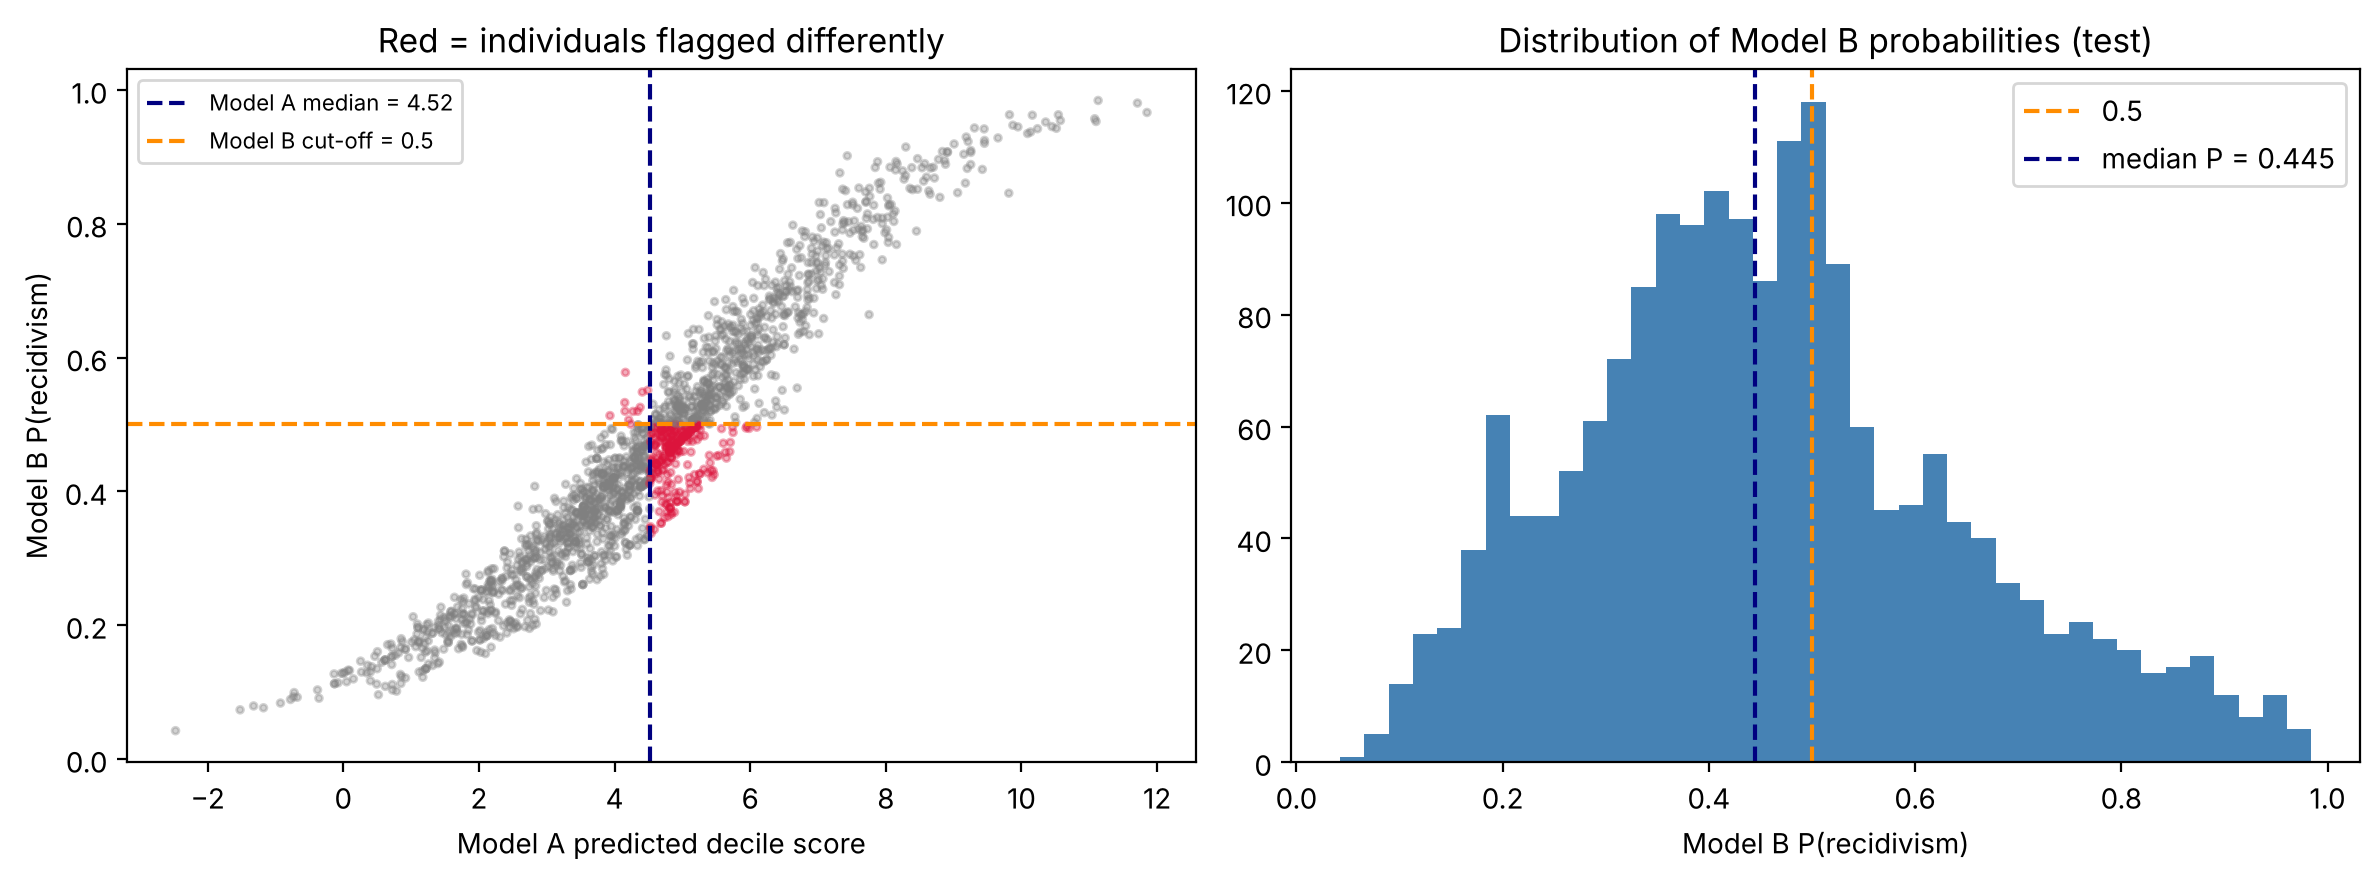

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(test.pred_A, test.prob_B, s=6, alpha=.35, c=np.where(test.high_A != test.high_B, "crimson", "grey"))
ax[0].axvline(median_A, ls="--", c="navy", label=f"Model A median = {median_A:.2f}")
ax[0].axhline(0.5, ls="--", c="darkorange", label="Model B cut-off = 0.5")
ax[0].set_xlabel("Model A predicted decile score"); ax[0].set_ylabel("Model B P(recidivism)")
ax[0].set_title("Red = individuals flagged differently"); ax[0].legend(fontsize=8)
ax[1].hist(test.prob_B, bins=40, color="steelblue")
ax[1].axvline(0.5, c="darkorange", ls="--", label="0.5")
ax[1].axvline(prob_at_median, c="navy", ls="--", label=f"median P = {prob_at_median:.3f}")
ax[1].set_xlabel("Model B P(recidivism)"); ax[1].set_title("Distribution of Model B probabilities (test)"); ax[1].legend()
plt.tight_layout(); plt.savefig("fig_part1.png", dpi=150); plt.show()

## 3. Part 2.1 — Simpson's paradox hunt
We search for a predictor whose coefficient changes sign when the data are split by one demographic variable. The split we report is **sex** (subgroup A = men, subgroup B = women) and the key predictor is **`race_African_American`** (being Black vs. the Caucasian reference), adjusting for all other features. Logistic regression is fit (unscaled features, `statsmodels`) on (1) the full cleaned dataset, (2) men only, (3) women only. A pooled model with a `race × female` interaction tests whether the difference between the subgroups is statistically significant.

In [11]:
def logit(data, feats, y="is_recidivist"):
    X = sm.add_constant(data[feats].astype(float))
    return sm.Logit(data[y], X).fit(disp=0)

F_NOSEX = [f for f in FEATURES if f != "male"]
men, women = df[df.male == 1], df[df.male == 0]
m_full = logit(df, FEATURES)        # full dataset (all features incl. sex)
m_men, m_women = logit(men, F_NOSEX), logit(women, F_NOSEX)

def row(m, v):
    ci = m.conf_int().loc[v]
    return dict(coef=m.params[v], ci_low=ci[0], ci_high=ci[1], p=m.pvalues[v], odds_ratio=np.exp(m.params[v]))

simpson = {}
for v in ["race_African_American", "juv_fel_count", "felony", "priors_count", "age"]:
    simpson[v] = {"Full": row(m_full, v), "Men (A)": row(m_men, v), "Women (B)": row(m_women, v)}
    print(f"\n=== {v} ===")
    print(pd.DataFrame(simpson[v]).T.round(4))
print("\nn: full", len(df), " men", len(men), " women", len(women))

# Is the race effect significantly different between men and women?  -> interaction model
dfi = df.assign(female=1 - df.male)
dfi["aa_x_female"] = dfi.race_African_American * dfi.female
dfi["juvfel_x_female"] = dfi.juv_fel_count * dfi.female
m_int = logit(dfi, F_NOSEX + ["female", "aa_x_female", "juvfel_x_female"])
print("\nInteraction model:"); print(m_int.summary2().tables[1].loc[["race_African_American", "aa_x_female", "juv_fel_count", "juvfel_x_female"]].round(4))
RESULTS["simpson"] = simpson
RESULTS["simpson_n"] = dict(full=len(df), men=len(men), women=len(women))
RESULTS["simpson_interaction"] = {k: dict(coef=m_int.params[k], p=m_int.pvalues[k],
                                  ci_low=m_int.conf_int().loc[k][0], ci_high=m_int.conf_int().loc[k][1])
                                  for k in ["aa_x_female", "juvfel_x_female"]}


=== race_African_American ===
             coef  ci_low  ci_high       p  odds_ratio
Full       0.0636 -0.0611   0.1884  0.3176      1.0657
Men (A)    0.1531  0.0140   0.2922  0.0309      1.1654
Women (B) -0.2925 -0.5808  -0.0043  0.0467      0.7464

=== juv_fel_count ===
             coef  ci_low  ci_high       p  odds_ratio
Full       0.0601 -0.1147   0.2349  0.5004      1.0619
Men (A)    0.0777 -0.1021   0.2575  0.3971      1.0808
Women (B) -0.2175 -1.2193   0.7842  0.6704      0.8045

=== felony ===
             coef  ci_low  ci_high       p  odds_ratio
Full       0.1758  0.0590   0.2926  0.0032      1.1922
Men (A)    0.1251 -0.0045   0.2547  0.0586      1.1333
Women (B)  0.3605  0.0820   0.6390  0.0112      1.4341

=== priors_count ===
             coef  ci_low  ci_high    p  odds_ratio
Full       0.1487  0.1324   0.1650  0.0      1.1603
Men (A)    0.1412  0.1240   0.1583  0.0      1.1516
Women (B)  0.2042  0.1526   0.2558  0.0      1.2265

=== age ===
             coef  ci_low  

                     mean                      count          
race_grp African-American Caucasian African-American Caucasian
sex                                                           
Female             0.3698    0.3527              549       482
Male               0.5552    0.4022             2626      1621

Mean priors_count by sex x race
race_grp  African-American  Caucasian
sex                                  
Female               2.534      1.813
Male                 4.594      2.431


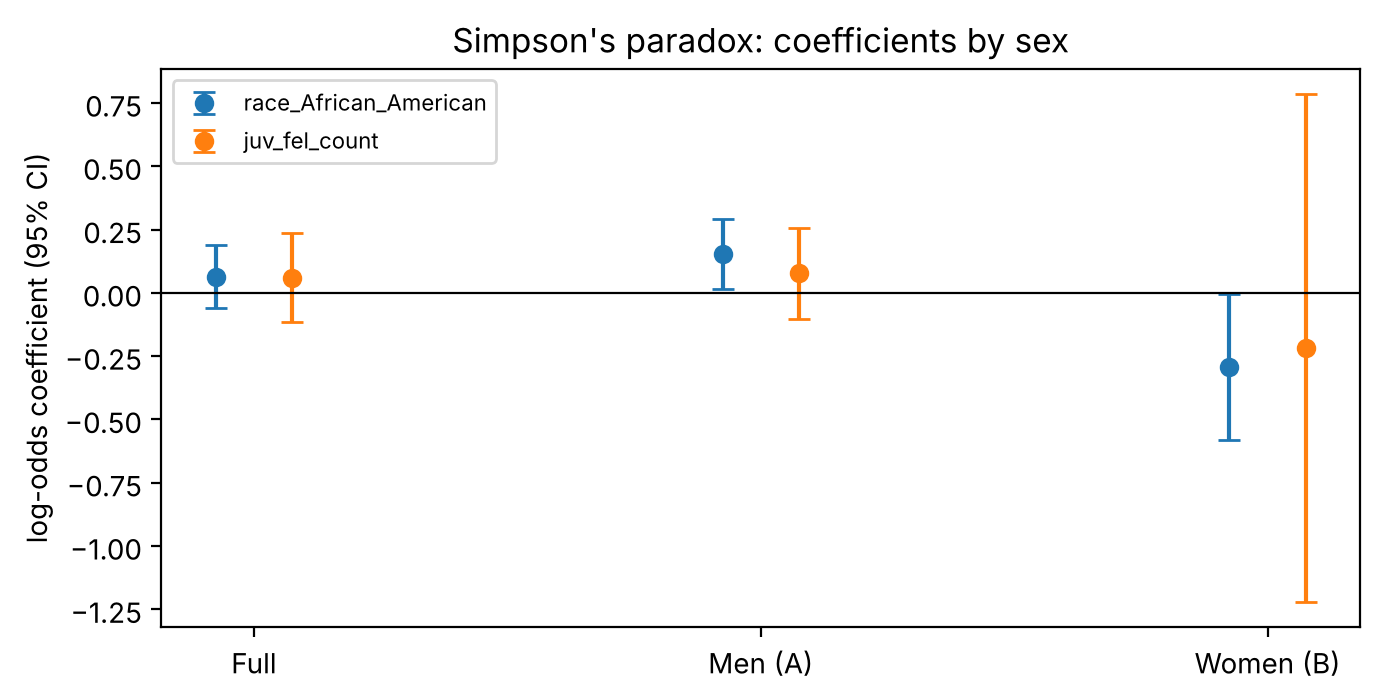

In [12]:
# Raw (unadjusted) recidivism rates by sex x race, to show where the reversal comes from
rates = df[df.race_grp.isin(["African-American", "Caucasian"])].pivot_table(
    index="sex", columns="race_grp", values="is_recidivist", aggfunc=["mean", "count"])
print(rates.round(4))
prior_means = df[df.race_grp.isin(["African-American", "Caucasian"])].pivot_table(
    index="sex", columns="race_grp", values="priors_count", aggfunc="mean")
print("\nMean priors_count by sex x race"); print(prior_means.round(3))
RESULTS["simpson_rates"] = {f"{s}|{r}": float(rates[("mean", r)][s]) for s in ["Male", "Female"] for r in ["African-American", "Caucasian"]}
RESULTS["simpson_counts"] = {f"{s}|{r}": int(rates[("count", r)][s]) for s in ["Male", "Female"] for r in ["African-American", "Caucasian"]}
RESULTS["simpson_priors"] = {f"{s}|{r}": float(prior_means[r][s]) for s in ["Male", "Female"] for r in ["African-American", "Caucasian"]}

fig, ax = plt.subplots(figsize=(7, 3.6))
labels = ["Full", "Men (A)", "Women (B)"]
for i, v in enumerate(["race_African_American", "juv_fel_count"]):
    c = [simpson[v][l]["coef"] for l in labels]
    lo = [simpson[v][l]["coef"] - simpson[v][l]["ci_low"] for l in labels]
    hi = [simpson[v][l]["ci_high"] - simpson[v][l]["coef"] for l in labels]
    ax.errorbar(np.arange(3) + i * 0.15, c, yerr=[lo, hi], fmt="o", capsize=4, label=v)
ax.axhline(0, c="k", lw=.8); ax.set_xticks(np.arange(3) + .075); ax.set_xticklabels(labels)
ax.set_ylabel("log-odds coefficient (95% CI)"); ax.set_title("Simpson's paradox: coefficients by sex"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_simpson.png", dpi=150); plt.show()

## 4. Part 2.2 — Omitted-variable bias
We deliberately drop **`priors_count`**. It is a plausible confounder: it strongly predicts recidivism *and* is correlated with race (via differential policing / arrest history), age (older people have had more time to accumulate priors) and the juvenile counts. Both models use the training set and unscaled features.

In [13]:
print("Correlation of priors_count with other features (training set):")
print(train[FEATURES].corr()["priors_count"].drop("priors_count").round(3))

m_fullmodel = logit(train, FEATURES)
F_RED = [f for f in FEATURES if f != "priors_count"]
m_reduced = logit(train, F_RED)
ovb = pd.DataFrame({"Full model": m_fullmodel.params[F_RED], "Reduced (no priors_count)": m_reduced.params[F_RED]})
ovb["Abs change"] = ovb.iloc[:, 1] - ovb.iloc[:, 0]
ovb["% change"] = 100 * ovb["Abs change"] / ovb["Full model"].abs()
ovb["p (full)"] = m_fullmodel.pvalues[F_RED]; ovb["p (reduced)"] = m_reduced.pvalues[F_RED]

print("\npriors_count coefficient in full model:", round(m_fullmodel.params["priors_count"], 4))
print(ovb.round(4))
most = ovb["% change"].abs().idxmax()
print("\nLargest % shift:", most, round(ovb.loc[most, "% change"], 2), "%")
acc_full = accuracy_score(test.is_recidivist, (m_fullmodel.predict(sm.add_constant(test[FEATURES].astype(float))) >= .5))
acc_red = accuracy_score(test.is_recidivist, (m_reduced.predict(sm.add_constant(test[F_RED].astype(float))) >= .5))
auc_full = roc_auc_score(test.is_recidivist, m_fullmodel.predict(sm.add_constant(test[FEATURES].astype(float))))
auc_red = roc_auc_score(test.is_recidivist, m_reduced.predict(sm.add_constant(test[F_RED].astype(float))))
print(f"Test accuracy full {acc_full:.4f} vs reduced {acc_red:.4f};  AUC {auc_full:.4f} vs {auc_red:.4f}")
print("Mean priors by race (train):"); print(train.groupby("race_grp").priors_count.mean().round(3))
RESULTS.update(dict(ovb=ovb.round(4).to_dict(orient="index"), ovb_most=most, priors_coef=m_fullmodel.params["priors_count"],
                    ovb_acc=(acc_full, acc_red), ovb_auc=(auc_full, auc_red),
                    priors_corr=train[FEATURES].corr()["priors_count"].round(3).to_dict(),
                    priors_by_race=train.groupby("race_grp").priors_count.mean().round(3).to_dict()))

Correlation of priors_count with other features (training set):
age                      0.120
male                     0.121
race_African_American    0.223
race_Hispanic           -0.063
race_Other              -0.077
juv_fel_count            0.192
juv_misd_count           0.274
juv_other_count          0.116
felony                   0.159
log_length_of_stay       0.249
Name: priors_count, dtype: float64



priors_count coefficient in full model: 0.1419
                       Full model  Reduced (no priors_count)  Abs change   % change  p (full)  p (reduced)
age                       -0.0411                    -0.0268      0.0143    34.8460    0.0000       0.0000
male                       0.2723                     0.3640      0.0916    33.6503    0.0015       0.0000
race_African_American      0.0168                     0.2589      0.2421  1441.9748    0.8241       0.0003
race_Hispanic             -0.2601                    -0.2170      0.0431    16.5611    0.0478       0.0878
race_Other                -0.2491                    -0.2666     -0.0175    -7.0170    0.0864       0.0608
juv_fel_count              0.0860                     0.3507      0.2647   307.6564    0.3932       0.0012
juv_misd_count            -0.0822                     0.2326      0.3148   383.0067    0.3410       0.0078
juv_other_count            0.2313                     0.3343      0.1030    44.5522    0.0033   

## 5. Part 2.3 — Adversarial subset construction
High-confidence errors of Model B on the test set: **P ≥ 0.75 but actual = 0** (confident false positive) or **P ≤ 0.25 but actual = 1** (confident false negative). We sample 50 of them with `random_state = 12`.

In [14]:
fp = test[(test.prob_B >= .75) & (test.is_recidivist == 0)]
fn = test[(test.prob_B <= .25) & (test.is_recidivist == 1)]
adv_all = pd.concat([fp.assign(err="confident FP"), fn.assign(err="confident FN")])
n_conf = int(((test.prob_B >= .75) | (test.prob_B <= .25)).sum())
print(f"Confident FP: {len(fp)}, confident FN: {len(fn)}, total {len(adv_all)} = "
      f"{100*len(adv_all)/len(test):.2f}% of test set; {100*len(adv_all)/n_conf:.2f}% of the {n_conf} confident predictions")
adv = adv_all.sample(n=min(50, len(adv_all)), random_state=SEED) if len(adv_all) > 50 else adv_all
print("Sample composition:", adv.err.value_counts().to_dict())

def profile(d):
    return pd.Series({"n": len(d), "mean age": d.age.mean(), "% age < 25": 100*(d.age < 25).mean(),
                      "% age 25-45": 100*d.age.between(25, 45).mean(), "% age > 45": 100*(d.age > 45).mean(),
                      "% male": 100*d.male.mean(), "% African-American": 100*(d.race_grp == "African-American").mean(),
                      "% Caucasian": 100*(d.race_grp == "Caucasian").mean(), "% Hispanic": 100*(d.race_grp == "Hispanic").mean(),
                      "% Other race": 100*(d.race_grp == "Other").mean(),
                      "mean priors": d.priors_count.mean(), "median priors": d.priors_count.median(),
                      "% priors = 0": 100*(d.priors_count == 0).mean(), "% priors >= 5": 100*(d.priors_count >= 5).mean(),
                      "% felony": 100*d.felony.mean(), "% any juvenile record": 100*((d.juv_fel_count+d.juv_misd_count+d.juv_other_count) > 0).mean(),
                      "mean decile_score": d.decile_score.mean(), "actual recid rate": 100*d.is_recidivist.mean(),
                      "mean P(recid)": d.prob_B.mean()})
adv_prof = pd.DataFrame({"Adversarial 50": profile(adv), "Confident FP (sample)": profile(adv[adv.err == "confident FP"]),
                         "Confident FN (sample)": profile(adv[adv.err == "confident FN"]), "Full test set": profile(test)})
print(adv_prof.round(2))
RESULTS.update(dict(adv_fp=len(fp), adv_fn=len(fn), adv_total=len(adv_all), adv_pct=100*len(adv_all)/len(test),
                    adv_conf=n_conf, adv_sample=adv.err.value_counts().to_dict(),
                    adv_profile=adv_prof.round(2).to_dict()))

Confident FP: 29, confident FN: 39, total 68 = 3.67% of test set; 17.17% of the 396 confident predictions
Sample composition: {'confident FN': 33, 'confident FP': 17}
                       Adversarial 50  Confident FP (sample)  Confident FN (sample)  Full test set
n                               50.00                  17.00                  33.00        1852.00
mean age                        45.62                  35.24                  50.97          33.78
% age < 25                       6.00                  17.65                   0.00          23.38
% age 25-45                     38.00                  70.59                  21.21          59.18
% age > 45                      56.00                  11.76                  78.79          17.44
% male                          76.00                 100.00                  63.64          80.99
% African-American              40.00                  70.59                  24.24          53.46
% Caucasian                     42.00    

In [15]:
# Common characteristics: the confident FPs vs. confident FNs live at opposite corners of (age, priors) space
fp_s, fn_s = adv[adv.err == "confident FP"], adv[adv.err == "confident FN"]
traits = {
  "FP: age < 25 OR priors >= 5": 100 * ((fp_s.age < 25) | (fp_s.priors_count >= 5)).mean(),
  "FP: priors >= 5": 100 * (fp_s.priors_count >= 5).mean(),
  "FP: age < 30": 100 * (fp_s.age < 30).mean(),
  "FN: age >= 30 AND priors <= 2": 100 * ((fn_s.age >= 30) & (fn_s.priors_count <= 2)).mean(),
  "FN: priors <= 1": 100 * (fn_s.priors_count <= 1).mean(),
  "FN: age >= 35": 100 * (fn_s.age >= 35).mean(),
  "ALL 50: 'textbook' profile (FP: young or many priors / FN: older and few priors)":
      100 * (((adv.err == "confident FP") & ((adv.age < 25) | (adv.priors_count >= 5))) |
             ((adv.err == "confident FN") & (adv.age >= 30) & (adv.priors_count <= 2))).mean(),
  "Test set: age < 25 OR priors >= 5": 100 * ((test.age < 25) | (test.priors_count >= 5)).mean(),
  "Test set: age >= 30 AND priors <= 2": 100 * ((test.age >= 30) & (test.priors_count <= 2)).mean(),
}
for k, v in traits.items(): print(f"{k:80s} {v:6.1f}%")
RESULTS["adv_traits"] = traits

# Why: does the model miss an age x priors interaction / non-linearity? Compare calibration in the extremes
test["priors_bin"] = pd.cut(test.priors_count, [-1, 0, 2, 4, 9, 40], labels=["0", "1-2", "3-4", "5-9", "10+"])
test["age_bin"] = pd.cut(test.age, [0, 24, 34, 44, 100], labels=["<25", "25-34", "35-44", "45+"])
calib = test.groupby("priors_bin").agg(n=("is_recidivist", "size"), actual=("is_recidivist", "mean"), predicted=("prob_B", "mean")).round(3)
print("\nCalibration by priors bin (test):"); print(calib)
calib_age = test.groupby("age_bin").agg(n=("is_recidivist", "size"), actual=("is_recidivist", "mean"), predicted=("prob_B", "mean")).round(3)
print("\nCalibration by age bin (test):"); print(calib_age)

# Test for a missing interaction / non-linearity on the training set
tr2 = train.assign(age_x_priors=train.age * train.priors_count, priors_sq=train.priors_count ** 2)
m_int2 = logit(tr2, FEATURES + ["age_x_priors", "priors_sq"])
print("\nAdded terms:"); print(m_int2.summary2().tables[1].loc[["age_x_priors", "priors_sq"]].round(5))
lr_stat = 2 * (m_int2.llf - m_fullmodel.llf)
from scipy.stats import chi2
print(f"Likelihood-ratio test vs. linear model: LR = {lr_stat:.3f}, p = {chi2.sf(lr_stat, 2):.5f}")
# How many of the 50 would still be confident errors with the richer model?
te2 = test.assign(age_x_priors=test.age * test.priors_count, priors_sq=test.priors_count ** 2)
p2 = m_int2.predict(sm.add_constant(te2[FEATURES + ["age_x_priors", "priors_sq"]].astype(float)))
adv_p2 = p2.loc[adv.index]
still = int((((adv.err == "confident FP") & (adv_p2 >= .75)) | ((adv.err == "confident FN") & (adv_p2 <= .25))).sum())
print(f"Of the 50 adversarial rows, {still} remain confident errors under the richer model")
RESULTS.update(dict(calib_priors=calib.reset_index().astype(str).to_dict(orient="records"),
                    calib_age=calib_age.reset_index().astype(str).to_dict(orient="records"),
                    int_terms={k: dict(coef=m_int2.params[k], p=m_int2.pvalues[k]) for k in ["age_x_priors", "priors_sq"]},
                    lr_stat=lr_stat, lr_p=chi2.sf(lr_stat, 2), adv_still=still))

FP: age < 25 OR priors >= 5                                                       100.0%
FP: priors >= 5                                                                    94.1%
FP: age < 30                                                                       17.6%
FN: age >= 30 AND priors <= 2                                                      87.9%
FN: priors <= 1                                                                    75.8%
FN: age >= 35                                                                     100.0%
ALL 50: 'textbook' profile (FP: young or many priors / FN: older and few priors)   92.0%
Test set: age < 25 OR priors >= 5                                                  45.0%
Test set: age >= 30 AND priors <= 2                                                31.2%

Calibration by priors bin (test):
              n  actual  predicted
priors_bin                        
0           629   0.288      0.344
1-2         576   0.396      0.411
3-4         221   0.588 

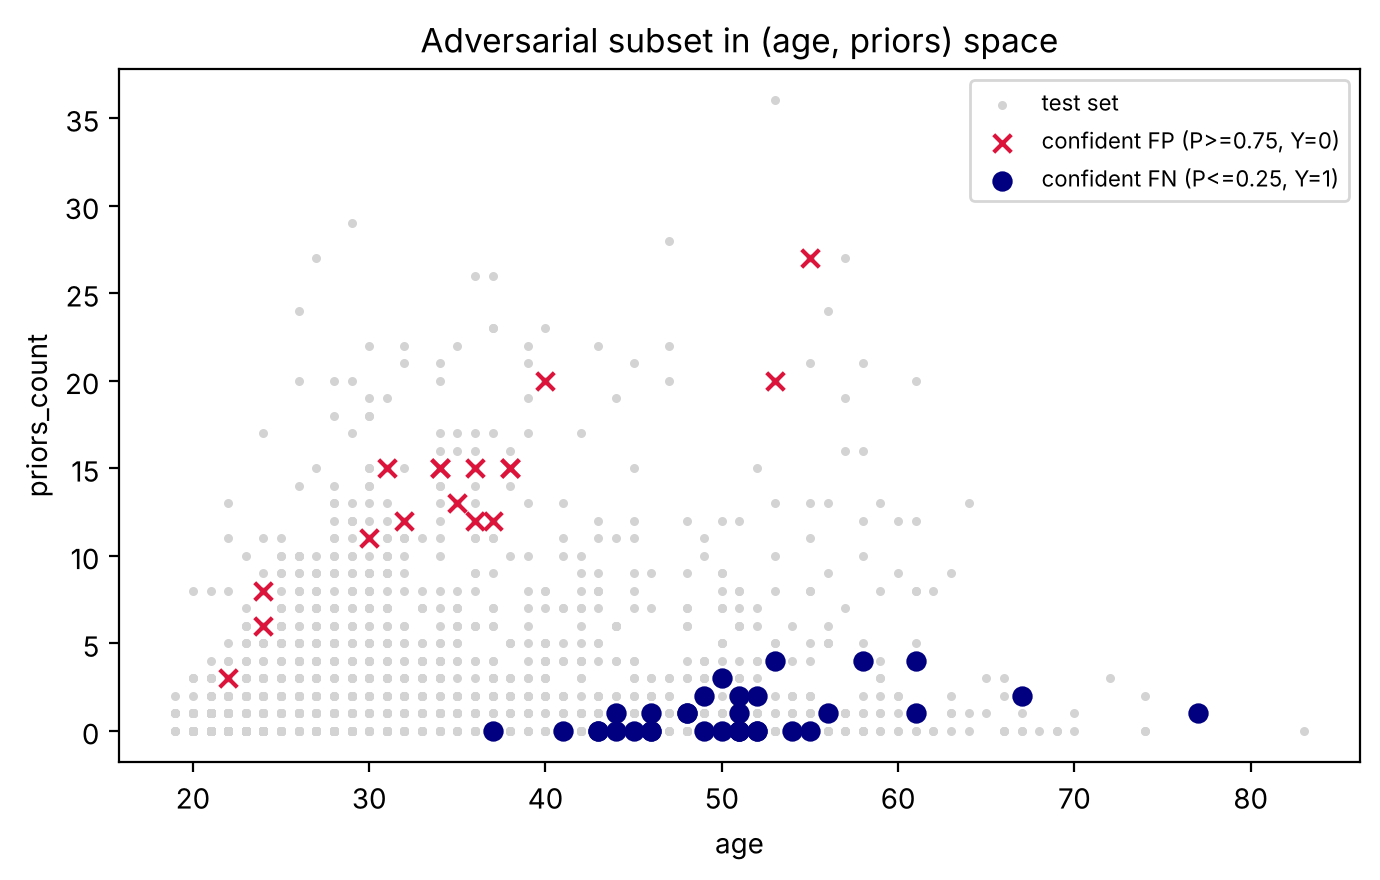

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(test.age, test.priors_count, s=5, c="lightgrey", label="test set")
ax.scatter(fp_s.age, fp_s.priors_count, s=40, c="crimson", marker="x", label="confident FP (P>=0.75, Y=0)")
ax.scatter(fn_s.age, fn_s.priors_count, s=40, c="navy", marker="o", facecolors="none", label="confident FN (P<=0.25, Y=1)")
ax.set_xlabel("age"); ax.set_ylabel("priors_count"); ax.set_title("Adversarial subset in (age, priors) space"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_adversarial.png", dpi=150); plt.show()

## 6. Part 2.4 — Fairness trade-off analysis
Sensitive variable: **race**. **Group A = Caucasian**, **Group B = African-American** (test set). We put the privileged group in the numerator so every ratio lies in the 0–1.5 range of the required chart, and so `min(TPR ratio, FPR ratio)` picks out the *larger* disparity (a ratio < 1 means Caucasian defendants are flagged/selected less often than African-American defendants). Threshold sweep t ∈ {0.05, 0.15, …, 0.95} on Model B's probabilities.
* DP = P(Ŷ=1|A) / P(Ŷ=1|B)
* EO = min(TPR_A/TPR_B, FPR_A/FPR_B)
* PP = P(Y=1|Ŷ=1,A) / P(Y=1|Ŷ=1,B)

A ratio is reported as `NaN` when its denominator is zero (e.g. nobody in Group B is flagged at a very high threshold).

In [17]:
A = test[test.race_grp == "Caucasian"]; B = test[test.race_grp == "African-American"]
print("Group A (Caucasian)        n =", len(A), " base rate", round(A.is_recidivist.mean(), 4))
print("Group B (African-American) n =", len(B), " base rate", round(B.is_recidivist.mean(), 4))

def rates(g, t):
    yhat = (g.prob_B >= t).astype(int); y = g.is_recidivist
    tp = ((yhat == 1) & (y == 1)).sum(); fp = ((yhat == 1) & (y == 0)).sum()
    pos = (y == 1).sum(); neg = (y == 0).sum()
    return dict(sel=yhat.mean(), tpr=tp / pos if pos else np.nan, fpr=fp / neg if neg else np.nan,
                ppv=tp / (tp + fp) if (tp + fp) else np.nan, acc=(yhat == y).mean())
div = lambda a, b: a / b if (b and not np.isnan(b) and b != 0) else np.nan

rows = []
for t in np.round(np.arange(0.05, 0.96, 0.1), 2):
    ra, rb = rates(A, t), rates(B, t)
    eo_t, eo_f = div(ra["tpr"], rb["tpr"]), div(ra["fpr"], rb["fpr"])
    rows.append(dict(threshold=t, DP=div(ra["sel"], rb["sel"]), TPR_ratio=eo_t, FPR_ratio=eo_f,
                     EO=np.nanmin([eo_t, eo_f]) if not (np.isnan(eo_t) and np.isnan(eo_f)) else np.nan,
                     PP=div(ra["ppv"], rb["ppv"]),
                     sel_A=ra["sel"], sel_B=rb["sel"], TPR_A=ra["tpr"], TPR_B=rb["tpr"], FPR_A=ra["fpr"], FPR_B=rb["fpr"],
                     PPV_A=ra["ppv"], PPV_B=rb["ppv"], acc_A=ra["acc"], acc_B=rb["acc"],
                     acc_all=accuracy_score(test.is_recidivist, (test.prob_B >= t).astype(int))))
fair = pd.DataFrame(rows).set_index("threshold")
print(fair[["DP", "EO", "PP", "TPR_ratio", "FPR_ratio", "acc_all"]].round(4))
print(); print(fair[["sel_A", "sel_B", "TPR_A", "TPR_B", "FPR_A", "FPR_B", "PPV_A", "PPV_B", "acc_A", "acc_B"]].round(4))
fair.to_csv("fairness_sweep.csv")
RESULTS["fair"] = fair.round(4).reset_index().to_dict(orient="records")
RESULTS["fair_groups"] = dict(nA=len(A), nB=len(B), baseA=A.is_recidivist.mean(), baseB=B.is_recidivist.mean())

Group A (Caucasian)        n = 596  base rate 0.3708
Group B (African-American) n = 990  base rate 0.5283
               DP      EO      PP  TPR_ratio  FPR_ratio  acc_all
threshold                                                       
0.05       1.0000  1.0000  0.7019     1.0000     1.0000   0.4557
0.15       0.9511  0.9279  0.7327     0.9928     0.9279   0.4816
0.25       0.8430  0.8046  0.7767     0.9328     0.8046   0.5427
0.35       0.7615  0.7290  0.8147     0.8838     0.7290   0.6285
0.45       0.5836  0.5860  0.8371     0.6960     0.5860   0.6895
0.55       0.4888  0.3790  0.9886     0.6884     0.3790   0.6766
0.65       0.4435  0.3874  0.9577     0.6051     0.3874   0.6361
0.75       0.3588  0.4057  0.7937     0.4057     0.5604   0.5977
0.85       0.3761  0.3113  0.9815     0.5259     0.3113   0.5707
0.95       0.4746  0.6761  1.0000     0.6761        NaN   0.5502

            sel_A   sel_B   TPR_A   TPR_B   FPR_A   FPR_B   PPV_A   PPV_B   acc_A   acc_B
threshold              

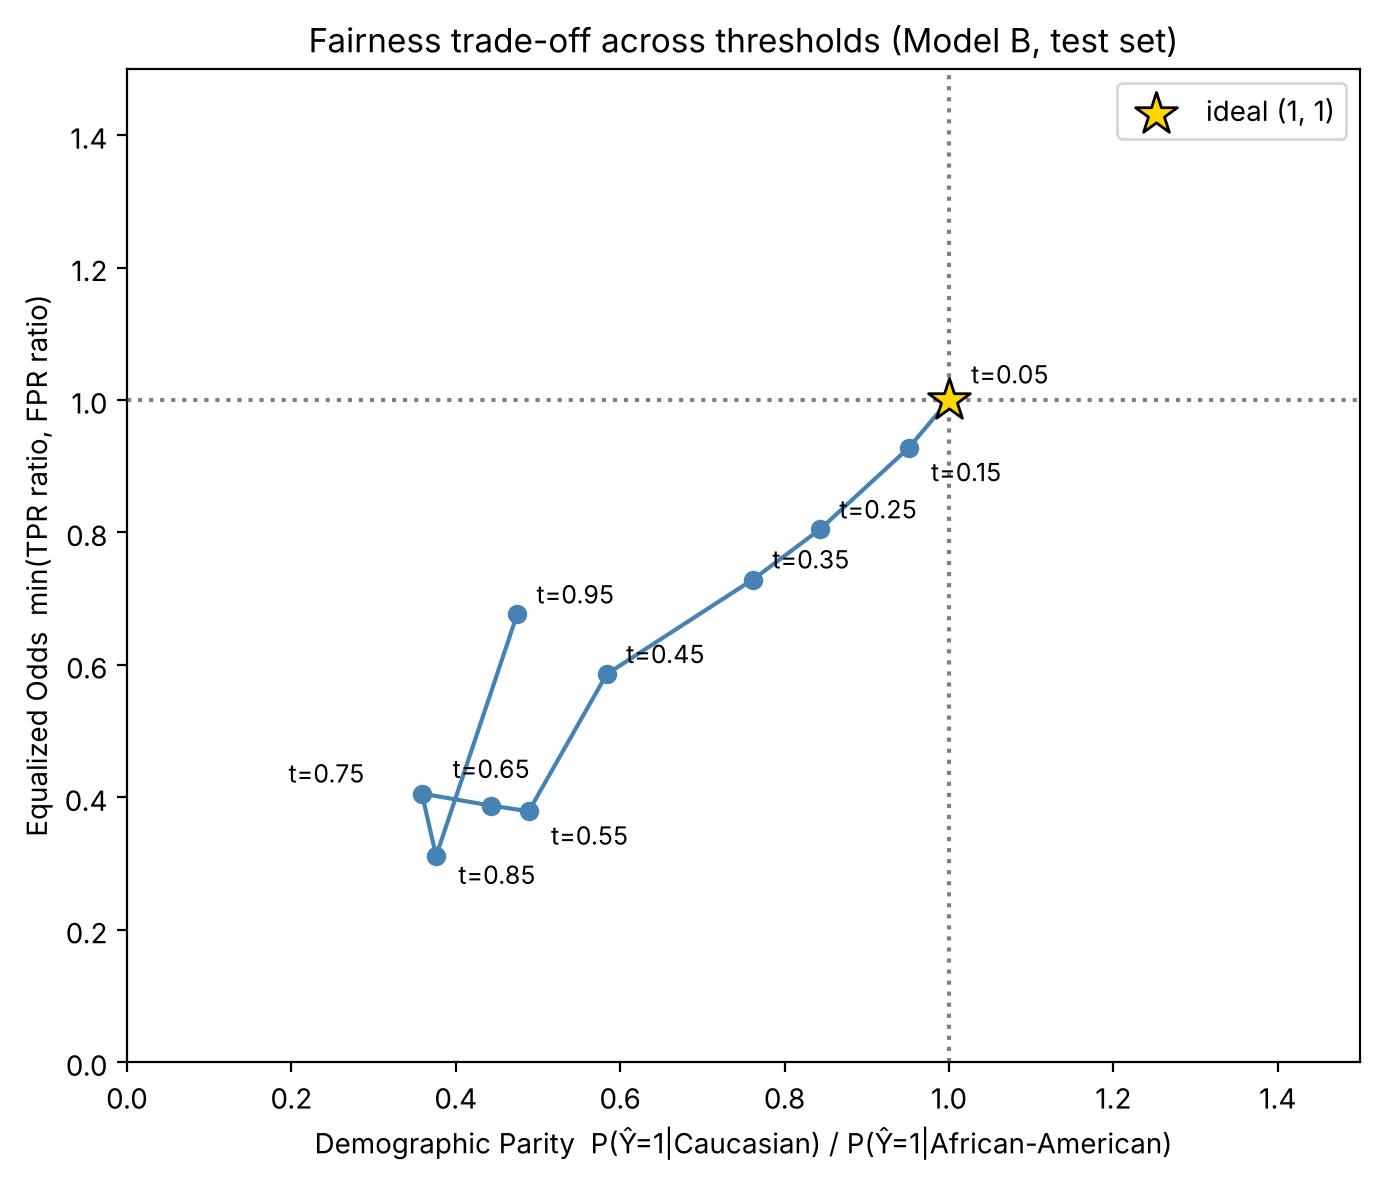

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
f = fair.dropna(subset=["DP", "EO"])
ax.plot(f.DP, f.EO, "-o", c="steelblue")
offs = {0.05: (8, 6), 0.15: (8, -12), 0.55: (8, -12), 0.65: (-14, 10), 0.75: (-48, 4), 0.85: (8, -10)}
for t, r in f.iterrows():
    ax.annotate(f"t={t:.2f}", (r.DP, r.EO), textcoords="offset points", xytext=offs.get(round(t, 2), (7, 4)), fontsize=9)
ax.scatter([1], [1], marker="*", s=250, c="gold", edgecolor="k", zorder=5, label="ideal (1, 1)")
ax.axvline(1, ls=":", c="grey"); ax.axhline(1, ls=":", c="grey")
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5)
ax.set_xlabel("Demographic Parity  P(Ŷ=1|Caucasian) / P(Ŷ=1|African-American)")
ax.set_ylabel("Equalized Odds  min(TPR ratio, FPR ratio)")
ax.set_title("Fairness trade-off across thresholds (Model B, test set)"); ax.legend()
plt.tight_layout(); plt.savefig("fig_fairness.png", dpi=150); plt.show()

In [19]:
# Quantify the trade-off for every move between adjacent thresholds:
# relative change (%) in each metric; "gain" = value moves toward 1, "loss" = moves away from 1.
f = fair.copy()
dist = lambda v: abs(v - 1)
moves = []
ts = list(f.index)
for t0 in ts:
    for t1 in ts:
        if t0 == t1: continue
        r0, r1 = f.loc[t0], f.loc[t1]
        if any(np.isnan(x) for x in [r0.DP, r1.DP, r0.EO, r1.EO, r0.PP, r1.PP]): continue
        moves.append(dict(from_t=t0, to_t=t1, DP_from=r0.DP, DP_to=r1.DP, DP_change_pct=100*(r1.DP-r0.DP)/r0.DP,
                          EO_from=r0.EO, EO_to=r1.EO, EO_change_pct=100*(r1.EO-r0.EO)/r0.EO,
                          PP_from=r0.PP, PP_to=r1.PP, PP_change_pct=100*(r1.PP-r0.PP)/r0.PP,
                          acc_from=r0.acc_all, acc_to=r1.acc_all,
                          DP_improves=dist(r1.DP) < dist(r0.DP), EO_improves=dist(r1.EO) < dist(r0.EO),
                          PP_improves=dist(r1.PP) < dist(r0.PP)))
moves = pd.DataFrame(moves)
# (a) Literal DP-vs-EO trade-off: adjacent moves where DP improves but EO gets worse
adj = moves[(moves.to_t - moves.from_t).abs().round(2) == 0.10]
dp_eo = adj[adj.DP_improves & ~adj.EO_improves].copy()
dp_eo["cost_W_over_Z"] = dp_eo.EO_change_pct.abs() / dp_eo.DP_change_pct.abs()
print("(a) Adjacent moves where DP improves but EO worsens:"); print(dp_eo.round(4).to_string())
# (b) DP-vs-PP trade-off from the conventional operating point (0.55 is the sweep value nearest 0.5)
dp_pp = moves[(moves.from_t == 0.55) & moves.DP_improves].copy()
dp_pp["cost_PP_over_DP"] = dp_pp.PP_change_pct.abs() / dp_pp.DP_change_pct.abs()
print("\n(b) Moves from t=0.55 that improve DP — what happens to EO, PP and accuracy:")
print(dp_pp[["from_t","to_t","DP_from","DP_to","DP_change_pct","EO_from","EO_to","EO_change_pct","PP_from","PP_to","PP_change_pct","acc_from","acc_to","cost_PP_over_DP"]].round(4).to_string())
# (c) Is there any threshold where all three are within 0.8–1.25 (the "four-fifths" band)?
band = fair[(fair.DP.between(.8, 1.25)) & (fair.EO.between(.8, 1.25)) & (fair.PP.between(.8, 1.25))]
print("\n(c) Thresholds with DP, EO and PP all inside [0.8, 1.25]:", list(band.index))
RESULTS["tradeoff_dp_eo"] = dp_eo.round(4).to_dict(orient="records")
RESULTS["tradeoff_dp_pp"] = dp_pp.round(4).to_dict(orient="records")
RESULTS["all_three_band"] = [float(x) for x in band.index]

(a) Adjacent moves where DP improves but EO worsens:
    from_t  to_t  DP_from   DP_to  DP_change_pct  EO_from   EO_to  EO_change_pct  PP_from   PP_to  PP_change_pct  acc_from  acc_to  DP_improves  EO_improves  PP_improves  cost_W_over_Z
59    0.65  0.55   0.4435  0.4888        10.2295   0.3874  0.3790        -2.1739   0.9577  0.9886         3.2190    0.6361  0.6766         True        False         True         0.2125
69    0.75  0.65   0.3588  0.4435        23.5964   0.4057  0.3874        -4.4989   0.7937  0.9577        20.6732    0.5977  0.6361         True        False         True         0.1907
70    0.75  0.85   0.3588  0.3761         4.8218   0.4057  0.3113       -23.2580   0.7937  0.9815        23.6667    0.5977  0.5707         True        False         True         4.8235

(b) Moves from t=0.55 that improve DP — what happens to EO, PP and accuracy:
    from_t  to_t  DP_from   DP_to  DP_change_pct  EO_from   EO_to  EO_change_pct  PP_from   PP_to  PP_change_pct  acc_from  acc_t

## 7. Summary of key numbers (saved to `results.json`)

In [20]:
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if np.isnan(o) else float(o)
    return o
with open("results.json", "w") as fh: json.dump(to_py(RESULTS), fh, indent=1)
for k in ["n_clean", "n_train", "n_test", "median_A", "mismatch", "mismatch_pct", "B_acc", "B_auc", "adv_total", "adv_pct"]:
    print(f"{k:15s}", RESULTS[k])

n_clean         6172
n_train         4320
n_test          1852
median_A        4.51884819046434
mismatch        279
mismatch_pct    15.064794816414686
B_acc           0.6879049676025918
B_auc           0.7530564186849787
adv_total       68
adv_pct         3.67170626349892
